# Od DN k odrazivosti, pokročilá verze: topografická korekce v Krkonoších

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/dn_to_reflectance_pro_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Od DN k odrazivosti](https://openskylab.space/edu_viz_dn_to_reflectance.html) · [English version](dn_to_reflectance_pro_en.ipynb)

Pokročilá verze notebooku k převodu DN na odrazivost. Vzorec pro odrazivost TOA dělí sinem výšky Slunce, tedy předpokládá rovinu. V horách ale každý svah dostává jiné osvětlení. Spočítáš ho z digitálního modelu terénu pro dvě scény Landsatu 8 s různou výškou Slunce, změříš, jak silně mění odrazivost lesa, a porovnáš pět topografických korekcí.

**Cíl:** spočítat sklon, orientaci a úhel dopadu slunečního záření z DEM, změřit vliv terénu na odrazivost v jednotlivých pásmech a ročních obdobích, porovnat kosinovou korekci, C-korekci, Minnaertovu korekci a SCS+C a posoudit, jak korekci poctivě ověřit.

**Data:** Landsat 8 OLI Collection 1 Level-1 z veřejného archivu Google Cloud: `LC08_L1TP_191025_20190626_20190705_01_T1` (26. 6. 2019, výška Slunce 60°) a `LC08_L1TP_191025_20181013_20181030_01_T1` (13. 10. 2018, výška Slunce 31°), pásma B2–B7, BQA a MTL; Copernicus DEM GLO-30 z registru AWS Open Data; třídy ESA WorldCover 2021 v200. Výřez 12 × 12 km ve východních Krkonoších, asi 25 MB.

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 70 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava a data

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
warnings.filterwarnings("ignore")

In [3]:
GCS = "https://storage.googleapis.com/gcp-public-data-landsat/LC08/01/191/025/"
SCENES = {"léto": "LC08_L1TP_191025_20190626_20190705_01_T1", "podzim": "LC08_L1TP_191025_20181013_20181030_01_T1"}   # ◀ parametr: dvě scény s různou výškou Slunce
LON, LAT, SIZE = 15.70, 50.70, 12000               # ◀ parametr: střed výřezu (Krkonoše) a jeho strana (m)
x, y = Transformer.from_crs(4326, 32633, always_xy=True).transform(LON, LAT)
X0, Y0 = round((x - SIZE / 2) / 30) * 30, round((y - SIZE / 2) / 30) * 30
BANDS = {2: "modrá", 3: "zelená", 4: "červená", 5: "NIR", 6: "SWIR1", 7: "SWIR2"}
DEM = "https://copernicus-dem-30m.s3.amazonaws.com/Copernicus_DSM_COG_10_N50_00_E015_00_DEM/Copernicus_DSM_COG_10_N50_00_E015_00_DEM.tif"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E015_Map.tif"
ENV = dict(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2)

def mtl(scene):
    txt = requests.get(f"{GCS}{scene}/{scene}_MTL.txt", timeout=60).text
    return {k.strip(): v.strip().strip('"') for k, v in (l.split(" = ") for l in txt.splitlines() if " = " in l)}

def read(scene, band):
    with rasterio.Env(**ENV), rasterio.open(f"/vsicurl/{GCS}{scene}/{scene}_{band}.TIF") as r:
        w = rasterio.windows.from_bounds(X0, Y0, X0 + SIZE, Y0 + SIZE, r.transform).round_offsets().round_lengths()
        read.transform = r.window_transform(w)
        return r.read(1, window=w).astype(float)

def on_grid(url, shape, resampling=Resampling.bilinear, dtype=np.float32):
    out = np.zeros(shape, dtype)
    with rasterio.Env(**ENV), rasterio.open("/vsicurl/" + url) as r:
        reproject(rasterio.band(r, 1), out, dst_transform=read.transform, dst_crs="EPSG:32633", resampling=resampling)
    return out

L8 = {}
for season, scene in SCENES.items():
    m = mtl(scene)
    el, az = float(m["SUN_ELEVATION"]), float(m["SUN_AZIMUTH"])
    toa = {b: (float(m[f"REFLECTANCE_MULT_BAND_{b}"]) * read(scene, f"B{b}") + float(m[f"REFLECTANCE_ADD_BAND_{b}"])) / np.sin(np.radians(el)) for b in BANDS}
    qa = read(scene, "BQA").astype(int)
    ok = ((qa >> 4) & 1 == 0) & ((qa >> 7) & 3 < 3) & (qa > 1)
    L8[season] = dict(toa=toa, el=el, az=az, ok=ok)
    print(f"{season}: {scene}, výška Slunce {el:.1f}°, azimut {az:.1f}°, jasné pixely {ok.mean():.1%}")
shape = L8["léto"]["toa"][2].shape
dem = on_grid(DEM, shape)
wc = on_grid(WORLDCOVER, shape, Resampling.mode, np.uint8)
print(f"výšky {dem.min():.0f}–{dem.max():.0f} m, les podle WorldCoveru {np.mean(wc == 10):.0%} výřezu")

léto: LC08_L1TP_191025_20190626_20190705_01_T1, výška Slunce 59.8°, azimut 146.4°, jasné pixely 99.8%


podzim: LC08_L1TP_191025_20181013_20181030_01_T1, výška Slunce 30.7°, azimut 164.3°, jasné pixely 99.8%


výšky 525–1602 m, les podle WorldCoveru 81% výřezu


## 2. Osvětlení svahu z modelu terénu

Na rovině dopadá přímé sluneční záření pod zenitovým úhlem θ_s, na svahu se sklonem s a orientací a pod úhlem i: cos i = cos θ_s · cos s + sin θ_s · sin s · cos(φ_s − a), kde φ_s je azimut Slunce. Přímé ozáření svahu je úměrné cos i; difuzní světlo oblohy dopadá ze všech směrů a na orientaci svahu závisí mnohem méně.

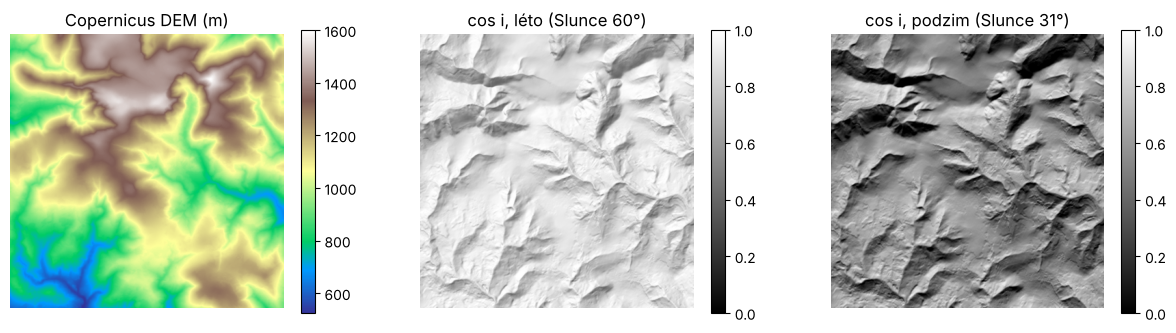

léto: cos i na rovině 0.86, ve výřezu 1.–99. percentil 0.46 až 0.99, ve vlastním stínu (cos i < 0) 0.0% pixelů
podzim: cos i na rovině 0.51, ve výřezu 1.–99. percentil -0.02 až 0.86, ve vlastním stínu (cos i < 0) 1.4% pixelů


In [4]:
dzdy, dzdx = np.gradient(dem, 30)                  # řádky jdou k jihu, sloupce k východu
dzdE, dzdN = dzdx, -dzdy
slope = np.arctan(np.hypot(dzdE, dzdN))
aspect = np.arctan2(-dzdE, -dzdN) % (2 * np.pi)    # kam svah hledí, ve stupních od severu po směru hodin
for s in L8.values():
    zs, az = np.radians(90 - s["el"]), np.radians(s["az"])
    s["cosi"] = np.cos(zs) * np.cos(slope) + np.sin(zs) * np.sin(slope) * np.cos(az - aspect)
    s["cosz"] = np.cos(zs)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
im = ax[0].imshow(dem, cmap="terrain"); ax[0].set_title("Copernicus DEM (m)"); fig.colorbar(im, ax=ax[0], shrink=0.8)
for a, (season, s) in zip(ax[1:], L8.items()):
    im = a.imshow(s["cosi"], cmap="gray", vmin=0, vmax=1); a.set_title(f"cos i, {season} (Slunce {s['el']:.0f}°)"); fig.colorbar(im, ax=a, shrink=0.8)
for a in ax: a.axis("off")
plt.show()
for season, s in L8.items():
    print(f"{season}: cos i na rovině {s['cosz']:.2f}, ve výřezu 1.–99. percentil {np.percentile(s['cosi'], 1):.2f} až {np.percentile(s['cosi'], 99):.2f}, "
          f"ve vlastním stínu (cos i < 0) {np.mean(s['cosi'] < 0):.1%} pixelů")

> **✏️ Úkol 1.** Porovnej mapy cos i v létě a na podzim. Proč se na podzim osvětlení jižních a severních svahů liší mnohem víc a kolik pixelů je ve vlastním stínu? Proč vzorec odrazivosti TOA z notebooku k vizuálu (dělení sinem výšky Slunce) na svahu nedává skutečnou odrazivost povrchu?

*Tvoje odpověď:* 

## 3. Jak silně terén mění odrazivost lesa

Vezmeme lesní pixely podle WorldCoveru a proložíme přímku ρ = m · cos i + b. Kdyby svah osvětlovalo jen přímé Slunce a les odrážel stejně do všech směrů, byla by odrazivost úměrná cos i a posun b by byl nulový. Poměr C = b/m je základem C-korekce (Teillet a kol. 1982).

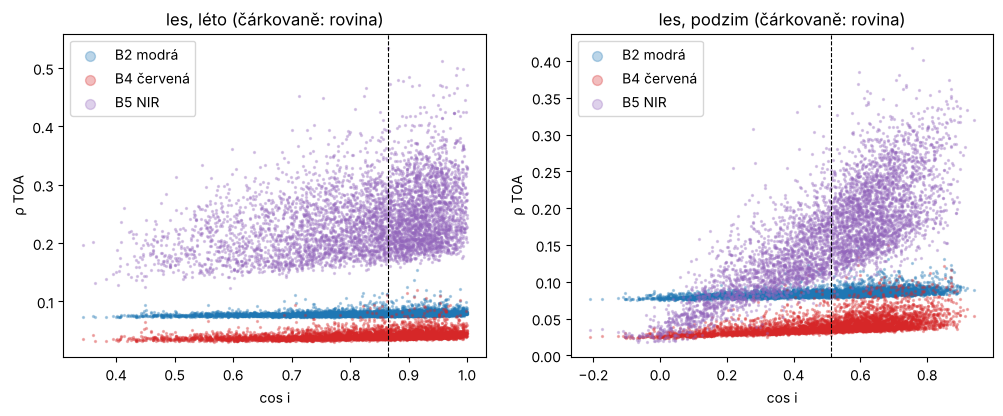

r  sklon m  posun b  C = b/m
období pásmo                                       
léto   B2 modrá    0.278    0.009    0.072    7.777
       B3 zelená   0.339    0.020    0.048    2.429
       B4 červená  0.316    0.019    0.026    1.384
       B5 NIR      0.342    0.146    0.117    0.804
       B6 SWIR1    0.366    0.095    0.019    0.201
       B7 SWIR2    0.338    0.048    0.004    0.092
podzim B2 modrá    0.499    0.013    0.078    6.030
       B3 zelená   0.631    0.029    0.044    1.510
       B4 červená  0.535    0.032    0.025    0.795
       B5 NIR      0.795    0.252    0.036    0.144
       B6 SWIR1    0.614    0.127   -0.000   -0.003
       B7 SWIR2    0.548    0.062   -0.002   -0.030

In [5]:
forest = (wc == 10) & (slope > np.radians(2))
rows, rng = [], np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (season, s) in zip(ax, L8.items()):
    f = forest & s["ok"]
    sel = rng.choice(np.flatnonzero(f.ravel()), 5000, replace=False)
    for b, col in [(2, "tab:blue"), (4, "tab:red"), (5, "tab:purple")]:
        a.scatter(s["cosi"].ravel()[sel], s["toa"][b].ravel()[sel], s=2, alpha=0.3, c=col, label=f"B{b} {BANDS[b]}")
    a.axvline(s["cosz"], color="k", lw=0.8, ls="--")
    a.set(xlabel="cos i", ylabel="ρ TOA", title=f"les, {season} (čárkovaně: rovina)"); a.legend(markerscale=5)
    for b in BANDS:
        k, q = np.polyfit(s["cosi"][f], s["toa"][b][f], 1)
        rows.append({"období": season, "pásmo": f"B{b} {BANDS[b]}", "r": np.corrcoef(s["cosi"][f], s["toa"][b][f])[0, 1],
                     "sklon m": k, "posun b": q, "C = b/m": q / k})
plt.show()
pd.DataFrame(rows).set_index(["období", "pásmo"]).round(3)

> **✏️ Úkol 2.** Ve kterém pásmu a období je vztah s cos i nejsilnější? Proč má modrá pásmo velké C, tedy velký posun ve srovnání se sklonem, a SWIR skoro nulové? Spoj to s podílem difuzního světla oblohy v jednotlivých vlnových délkách.

*Tvoje odpověď:* 

## 4. Pět korekcí

Kosinová korekce ρ · cos θ_s / cos i předpokládá jen přímé světlo. C-korekce přidá C do čitatele i jmenovatele, Minnaertova korekce ρ · (cos θ_s / cos i)^k odhadne exponent k z dat a SCS+C (Soenen a kol. 2005) bere v úvahu, že stromy rostou svisle, ne kolmo ke svahu. Hodnotíme korelaci s cos i po korekci, rozptyl odrazivosti lesa a poměr mediánů na strmých jižních a severních svazích (u stejného lesa by měl být blízko 1).

In [6]:
COSI_MIN = 0.15        # ◀ parametr: pixely s cos i pod touto hodnotou se neopravují (skoro ve stínu)

def correct(rho, cosi, cosz, slope, method, f):
    """Topografická korekce odrazivosti rho; parametry metod (C, k) se odhadují na pixelech f."""
    if method == "žádná":
        return rho
    if method == "kosinová":
        return rho * cosz / cosi
    if method == "C":
        m, b = np.polyfit(cosi[f], rho[f], 1)
        return rho * (cosz + b / m) / (cosi + b / m)
    if method == "Minnaert":
        k = np.polyfit(np.log(cosi[f] / cosz), np.log(rho[f]), 1)[0]
        return rho * (cosz / cosi) ** k
    if method == "SCS+C":
        m, b = np.polyfit(cosi[f], rho[f], 1)
        return rho * (np.cos(slope) * cosz + b / m) / (cosi + b / m)
    raise ValueError(method)

METHODS = ["žádná", "kosinová", "C", "Minnaert", "SCS+C"]
sunny, shady = (np.degrees(aspect) > 135) & (np.degrees(aspect) < 225), (np.degrees(aspect) < 45) | (np.degrees(aspect) > 315)
rows = []
for season, s in L8.items():
    f = forest & s["ok"] & (s["cosi"] > COSI_MIN)
    steep = f & (slope > np.radians(15))
    for b in [2, 4, 5, 6]:
        for meth in METHODS:
            c = correct(s["toa"][b], s["cosi"], s["cosz"], slope, meth, f)
            q25, q50, q75 = np.percentile(c[f], [25, 50, 75])
            rows.append({"období": season, "pásmo": f"B{b}", "metoda": meth, "r s cos i": np.corrcoef(s["cosi"][f], c[f])[0, 1],
                         "rozptyl (IQR/medián)": (q75 - q25) / q50,
                         "jižní/severní svahy": np.median(c[steep & sunny]) / np.median(c[steep & shady])})
res = pd.DataFrame(rows).set_index(["období", "pásmo", "metoda"])
res.round(3)

r s cos i  rozptyl (IQR/medián)  jižní/severní svahy
období pásmo metoda                                                        
léto   B2    žádná         0.278                 0.051                1.039
             kosinová     -0.934                 0.212                0.706
             C            -0.001                 0.047                1.002
             Minnaert      0.014                 0.048                1.004
             SCS+C         0.038                 0.047                1.004
       B4    žádná         0.316                 0.170                1.148
             kosinová     -0.585                 0.249                0.769
             C            -0.006                 0.162                0.991
             Minnaert      0.024                 0.161                1.004
             SCS+C         0.041                 0.156                0.997
       B5    žádná         0.342                 0.324                1.223
             kosinová     -0.413                 0.337                0.804
             C            -0.005                 0.319                1.005
             Minnaert      0.010                 0.319                1.012
             SCS+C         0.045                 0.314                1.013
       B6    žádná         0.366                 0.480                1.386
             kosinová     -0.144                 0.454                0.900
             C            -0.017                 0.449                0.988
             Minnaert      0.014                 0.450                1.012
             SCS+C         0.041                 0.446                1.000
podzim B2    žádná         0.428                 0.066                1.074
             kosinová     -0.893                 0.485                0.339
             C            -0.002                 0.058                0.993
             Minnaert      0.041                 0.059                0.996
             SCS+C        -0.008                 0.057                0.991
       B4    žádná         0.469                 0.312                1.455
             kosinová     -0.699                 0.457                0.446
             C            -0.012                 0.258                0.951
             Minnaert      0.054                 0.265                0.981
             SCS+C        -0.019                 0.252                0.947
       B5    žádná         0.724                 0.490                2.445
             kosinová     -0.381                 0.359                0.762
             C            -0.008                 0.352                1.053
             Minnaert     -0.002                 0.353                1.041
             SCS+C        -0.020                 0.352                1.034
       B6    žádná         0.554                 0.785                3.379
             kosinová      0.031                 0.602                1.054
             C            -0.057                 0.603                0.913
             Minnaert      0.010                 0.601                1.020
             SCS+C        -0.063                 0.587                0.896

> **✏️ Úkol 3.** Která metoda překorigovává (záporné r, poměr jižních a severních svahů pod 1) a proč nejvíc v modré a na podzim? Proč u C, Minnaertovy korekce a SCS+C vychází r skoro přesně nula a proč to samo o sobě nedokazuje, že korekce funguje? Navrhni poctivější ověření (např. odhad parametrů na jedné polovině výřezu a hodnocení na druhé).

*Tvoje odpověď:* 

## 5. Mapy a vegetační index

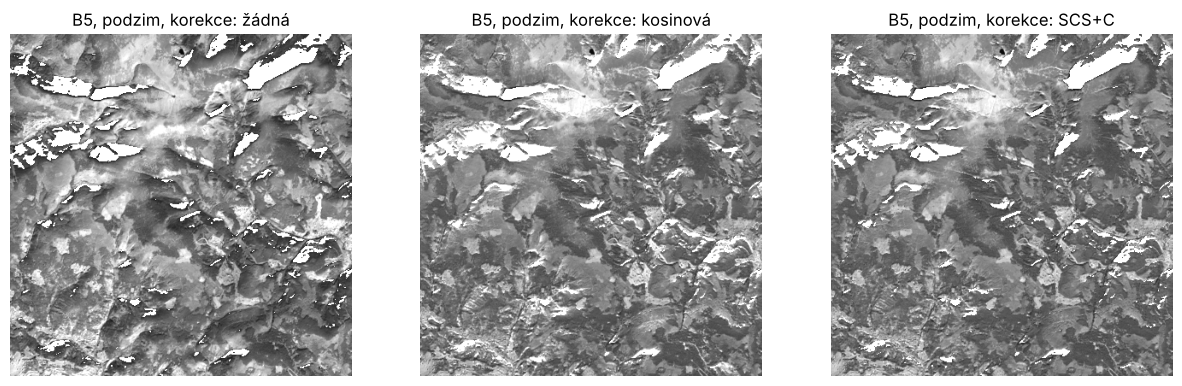

léto: korelace s cos i v lese: NIR 0.34, červená 0.32, NDVI 0.13
podzim: korelace s cos i v lese: NIR 0.79, červená 0.53, NDVI 0.75


In [7]:
SHOW, BAND = "podzim", 5           # ◀ parametr: období a pásmo pro mapy
s = L8[SHOW]
f = forest & s["ok"] & (s["cosi"] > COSI_MIN)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for a, meth in zip(ax, ["žádná", "kosinová", "SCS+C"]):
    c = np.where(s["cosi"] > COSI_MIN, correct(s["toa"][BAND], s["cosi"], s["cosz"], slope, meth, f), np.nan)
    a.imshow(c, cmap="gray", vmin=0, vmax=np.nanpercentile(s["toa"][BAND], 99)); a.set_title(f"B{BAND}, {SHOW}, korekce: {meth}"); a.axis("off")
plt.show()
ndvi = {season: (v["toa"][5] - v["toa"][4]) / (v["toa"][5] + v["toa"][4]) for season, v in L8.items()}
for season, v in L8.items():
    fs = forest & v["ok"]
    print(f"{season}: korelace s cos i v lese: NIR {np.corrcoef(v['cosi'][fs], v['toa'][5][fs])[0, 1]:.2f}, "
          f"červená {np.corrcoef(v['cosi'][fs], v['toa'][4][fs])[0, 1]:.2f}, NDVI {np.corrcoef(v['cosi'][fs], ndvi[season][fs])[0, 1]:.2f}")

> **✏️ Úkol 4.** Kde v opravené mapě zůstávají chyby (strmé severní svahy, místa pod `COSI_MIN`)? Nastav `COSI_MIN` na 0,05 a na 0,3 a popiš rozdíl. Proč kosinová korekce dělá ze stinných svahů nejjasnější místa scény?

*Tvoje odpověď:* 

> **✏️ Úkol 5.** V létě NDVI s cos i skoro nekoreluje, na podzim ano. Proč poměrový index vliv terénu vyruší jen tehdy, když je efekt čistě násobný? Které dva rozdíly mezi červenou a NIR (podíl difuzního světla z kroku 3, zář dráhy) to při nízkém Slunci kazí?

*Tvoje odpověď:* 

> **✏️ Rozšíření (nepovinné).** Přesuň výřez do Šumavy (dlaždici DEM a WorldCoveru je pak třeba změnit, scény Landsatu musí pokrývat nové místo) nebo použij místo lesa louky (`wc == 30`). Vyjdou parametry C a k podobně?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Landsat 8 OLI Collection 1 Level-1, U.S. Geological Survey; veřejný archiv Google Cloud (`gcp-public-data-landsat`). Data USGS jsou bez omezení užití, s uvedením zdroje.
- Copernicus DEM GLO-30: produced using Copernicus WorldDEM-30 © DLR e.V. 2010-2014 and © Airbus Defence and Space GmbH 2014-2018 provided under COPERNICUS by the European Union and ESA; all rights reserved. Registr AWS Open Data (`copernicus-dem-30m`).
- Zanaga, D. a kol. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Teillet, P. M., Guindon, B., Goodenough, D. G. (1982). On the slope-aspect correction of multispectral scanner data. *Canadian Journal of Remote Sensing* 8(2), 84–106.
- Minnaert, M. (1941). The reciprocity principle in lunar photometry. *Astrophysical Journal* 93, 403–410.
- Soenen, S. A., Peddle, D. R., Coburn, C. A. (2005). SCS+C: a modified sun-canopy-sensor topographic correction in forested terrain. *IEEE Transactions on Geoscience and Remote Sensing* 43, 2148–2159. https://doi.org/10.1109/TGRS.2005.852480

### Jak citovat

OpenSkyLab (2026). Od DN k odrazivosti, pokročilá verze: topografická korekce v Krkonoších [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/dn_to_reflectance_pro_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*